# Artículo: Replicación de Anselin et al. (1996)
* **Nombre**: Sierra Wells  
* **Clase**: Programación (Geointeligencia Computacional)
* **Programa**: Maestría en Ciencias de Información Geoespacial
* **Fecha**: 19 noviembre 2026

## Resumen
Se replica la metodología de Anselin et al. (1996), *Simple diagnostic tests for spatial dependence*.

Este notebook ajusta un modelo por mínimos cuadrados ordinarios (MCO, o OLS por sus siglas en inglés) de la tasa de homicidios de 2018 por municipio, a partir de los microdatos de defunciones registradas (Instituto Nacional de Estadística y Geografía [INEGI], 2018–2024). Como predictores, se incluyen variables socioeconómicas/demográficas del Censo de Población y Vivienda 2010 (INEGI, 2010a), así como el número de grupos criminales con presencia violenta en 2017, de la base de datos OCVED (Osorio y Beltrán, 2020).

Con los residuos del modelo MCO, se calculan las pruebas de multiplicadores de Lagrange (LM) para el error y rezago espacial, en sus versiones estándar y robustas. Los residuos presentan una autocorrelación espacial positiva y significativa ($I$ de Moran = 0.37), y las pruebas no robustas detectan tanto rezago como error espacial. Sin embargo, con las pruebas robustas solo el rezago espacial sigue siendo significativo, lo cual indica que un modelo de rezago espacial es la especificación más adecuada y es consistente con un "contagio" de la violencia homicida entre municipios vecinos.

## ¿Qué son el error y el rezago espacial?
_Rezago espacial_ ($\phi$): se observa cuando existe "contagio" espacial de la variable dependiente $y$ desde una unidad espacial hacia sus vecinos. En el contexto de este ejemplo, la presencia de rezago espacial significaría que la tasa de homicidios de cada municipio $i$ responde a las tasas de sus municipios vecinos. Es decir, cuando aumenta la tasa de homicidios en los vecinos de $i$, $i$ se "contagia" y aumenta su tasa también.

_Error espacial_ ($\psi$): existe cuando se omite del modelo un predictor importante que se concentra espacialmente. En el contexto de este ejercicio, la existencia del error espacial significaría que la concentración espacial de los residuos se debe a que se omitió una variable, como por ejemplo la presencia de un grupo específico del crimen organizado, que ayuda a explicar la discrepancia entre $y$ y $\hat{y}$.

## Sobre la estructura de este proyecto

El código y los datos necesarios para reproducir este proyecto están disponibles en [este](https://github.com/sierrawells/article-progra-cg) repositorio de GitHub. Antes del presente notebook, se llevó a cabo una limpieza sencilla de los datos de insumo del presente modelo. El código utilizado para realizar esta limpieza se puede encontrar en el subdirectorio `clean/src/`. Para más información, véase el `README.md` del repositorio.

In [1]:
# Librerías
from pathlib import Path

import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from esda.smoothing import Empirical_Bayes
from libpysal.weights import Queen
from scipy.stats import kurtosis, skew
from spreg import LMtests, OLS
from spreg.diagnostics_sp import MoranRes
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
# Rutas
TASK_DIR = Path.cwd().parent
INPUT_DIR = TASK_DIR / 'input'

In [3]:
# Escala de la tasa de homicidios (por cada 100 mil habitantes)
RATE_SCALE = 100_000

# Predictores: del censo 2010 y de OCVED (número de grupos criminales en 2017), elegidos por selección hacia adelante (ver la sección 2.3)
PREDICTORS = ['avg_schooling', 'pct_female_head', 'pct_indigenous_lang', 'pct_born_other_state', 'n_criminal_groups']

## 1. Leer datos

In [4]:
# Bases por municipio (una fila por cve_mun)
homicides_mun = pd.read_csv(INPUT_DIR / '1_clean_homicides.csv', dtype={'cve_mun': str})
sociodem_mun = pd.read_csv(INPUT_DIR / '2_clean_sociodem.csv', dtype={'cve_mun': str, 'cve_ent': str})
ocved_mun = pd.read_csv(INPUT_DIR / '3_clean_ocved.csv', dtype={'cve_mun': str})

# Polígonos municipales del Marco Geoestadístico 2010
muns = gpd.read_file(INPUT_DIR / 'municipios.shp')
muns = muns.assign(cve_mun=muns['CVE_ENT'] + muns['CVE_MUN']).set_index('cve_mun')

## 2. El modelo MCO

**2.1 Unir las bases**

In [5]:
# Una fila por municipio del censo 2010. Las bases de homicidios y de OCVED solo tienen los municipios
# con al menos un homicidio o un grupo identificado, así que los demás quedan en 0
model_data_mun = (
    sociodem_mun.set_index('cve_mun')[['nom_ent', 'nom_mun', 'pob_tot'] + [p for p in PREDICTORS if p != 'n_criminal_groups']]
    .join(ocved_mun.set_index('cve_mun')[['n_criminal_groups']])
    .join(homicides_mun.set_index('cve_mun'))
    .fillna({'n_criminal_groups': 0, 'homicides': 0})
    .astype({'n_criminal_groups': int, 'homicides': int})
)

model_data_mun['hom_rate'] = model_data_mun['homicides'] / model_data_mun['pob_tot'] * RATE_SCALE

# Revisiones: todos los municipios de homicidios y de OCVED están en el censo, así que no se pierde ningún registro
assert len(model_data_mun) == 2456

# Revisión: todos los municipios tienen tasa (población mayor a 0)
assert model_data_mun['hom_rate'].notna().all()

model_data_mun.head()

,nom_ent,nom_mun,pob_tot,avg_schooling,pct_female_head,pct_indigenous_lang,pct_born_other_state,n_criminal_groups,homicides,hom_rate
cve_mun,,,,,,,,,,
01001,Aguascalientes,Aguascalientes,797010,9.81,24.029820,0.239020,23.459179,0,55,6.900792
01002,Aguascalientes,Asientos,45492,7.25,16.208654,0.111235,11.417392,1,5,10.990943
01003,Aguascalientes,Calvillo,54136,6.90,22.884525,0.193489,11.783287,0,4,7.388799
01004,Aguascalientes,Cosío,15042,7.83,15.670996,0.120893,9.161016,0,0,0.000000
01005,Aguascalientes,Jesús María,99590,8.60,17.491011,0.194181,16.367105,0,5,5.020584


**2.2 Variable de respuesta: tasa de homicidios suavizada**

La tasa municipal de homicidios tiene dos problemas:
* **Muchos ceros:** el 35% de los municipios no registró ningún homicidio en 2018.
* **Tasas inestables:** en los municipios con poca población, uno o dos homicidios más o menos cambian mucho la tasa. La varianza de la tasa es mayor mientras menor es la población, lo que produce heterocedasticidad.

El suavizamiento bayesiano empírico (BE) global atiende los dos problemas (Marshall, 1991). La tasa suavizada de cada municipio es un promedio ponderado de su propia tasa, $r_i$, y de la tasa nacional, $b$:

$$r_i^{BE} = w_i \, r_i + (1 - w_i) \, b$$

donde el peso $w_i$ crece con la población del municipio: las tasas de los municipios grandes casi no cambian, y las de los municipios pequeños (incluidos los que tienen 0 homicidios) se acercan a la tasa nacional.

Una limitación a tener en cuenta: la población del denominador es la del censo de 2010, mientras que los homicidios son de 2018, por lo que la tasa está sobrestimada en los municipios cuya población creció entre esos años.

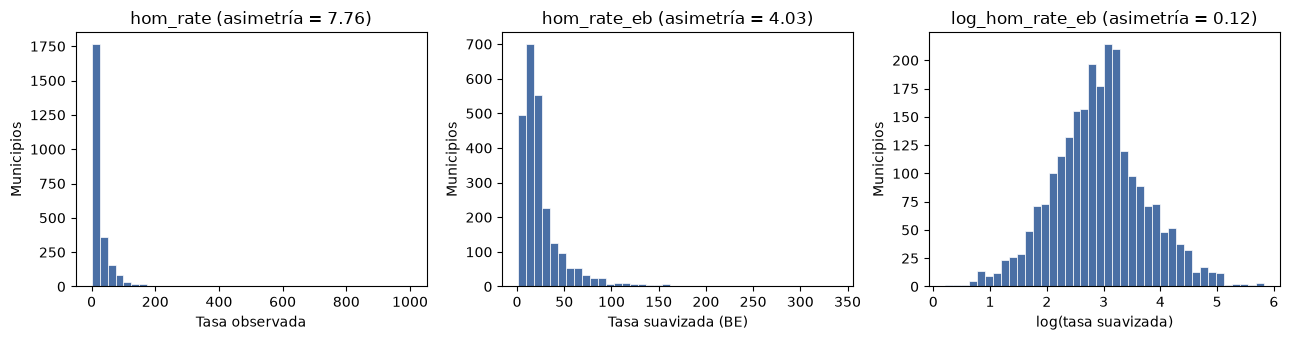

In [6]:
# Suavizamiento bayesiano empírico global (esda): homicidios y población de cada municipio
eb = Empirical_Bayes(model_data_mun[['homicides']].to_numpy(), model_data_mun[['pob_tot']].to_numpy())
model_data_mun['hom_rate_eb'] = eb.r.ravel() * RATE_SCALE

# Revisión: el suavizamiento no deja ceros, así que se puede tomar el logaritmo
assert (model_data_mun['hom_rate_eb'] > 0).all()
model_data_mun['log_hom_rate_eb'] = np.log(model_data_mun['hom_rate_eb'])

# Histogramas de la tasa observada, la tasa suavizada y su logaritmo
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, column, xlabel in zip(axes, ['hom_rate', 'hom_rate_eb', 'log_hom_rate_eb'], ['Tasa observada', 'Tasa suavizada (BE)', 'log(tasa suavizada)']):
    ax.hist(model_data_mun[column], bins=40, color='#4a6fa5', edgecolor='white', linewidth=0.5)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Municipios')
    ax.set_title(f'{column} (asimetría = {model_data_mun[column].skew():.2f})')
fig.tight_layout()

La tasa suavizada está muy asimétrica a la derecha, con una asimetría de 4.03. Los valores de la asimetría se interpretan así:

| $< -1$ | $-1$ a $-0.5$ | $-0.5$ a $0.5$ | $0.5$ a $1$ | $> 1$ |
|:---|:---:|:---:|:---:|---:|
| ⟵ **Muy asimétrica** (cola a la izquierda) | **Asimetría moderada** (cola a la izquierda) | **Relativamente simétrica** | **Asimetría moderada** (cola a la derecha) | **Muy asimétrica** (cola a la derecha) ⟶ |

MCO no exige que la variable de respuesta sea normal, pero si está muy sesgada, los residuos suelen ser también sesgados y heterocedásticos, y unos pocos municipios con tasas extremas pesan demasiado en la estimación; además, las pruebas LM de Anselin et al. (1996) suponen errores normales.

Dada la asimetría en la tasa, se transforma con $\log(\text{tasa})$, que tiene una asimetría de 0.12.

**2.3 Selección de predictores y colinealidad**

Los 5 predictores se eligieron con **selección hacia adelante** (*forward selection*) entre todos los indicadores del censo y `n_criminal_groups`: en cada paso se agregó el candidato con la mayor reducción estadísticamente significativa del error cuadrático medio (ECM, o MSE por sus siglas en inglés) con $\alpha = 0.05$.

Los modelos MCO asumen que *no hay* colinealidad problemática entre predictores. Aquí confirmamos que es así.

In [7]:
# Correlación (Pearson) entre los predictores, solo el triángulo superior (la matriz es simétrica)
corr = model_data_mun[PREDICTORS].corr()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).dropna(how='all').dropna(axis=1, how='all')
upper.style.format('{:.2f}', na_rep='')

,pct_female_head,pct_indigenous_lang,pct_born_other_state,n_criminal_groups
avg_schooling,0.17,-0.51,0.51,0.27
pct_female_head,,-0.11,0.10,0.07
pct_indigenous_lang,,,-0.34,-0.13
pct_born_other_state,,,,0.20


In [8]:
# Factor de inflación de la varianza (VIF); valores mayores a 5 indican colinealidad problemática
X_const = sm.add_constant(model_data_mun[PREDICTORS])
vif_mun = pd.Series([variance_inflation_factor(X_const.values, i) for i in range(1, X_const.shape[1])], index=PREDICTORS, name='VIF')
vif_mun.round(2)

avg_schooling           1.71
pct_female_head         1.03
pct_indigenous_lang     1.37
pct_born_other_state    1.37
n_criminal_groups       1.08
Name: VIF, dtype: float64

**2.4 Ajuste del modelo MCO**

$$\log(\text{tasa}^{BE}) = \gamma_0 + \gamma_1 \, \text{avg\_schooling} + \gamma_2 \, \text{pct\_female\_head} + \gamma_3 \, \text{pct\_indigenous\_lang} + \gamma_4 \, \text{pct\_born\_other\_state} + \gamma_5 \, \text{n\_criminal\_groups} + \varepsilon$$

En notación matricial, como en Anselin et al. (1996), es el modelo $y = X\gamma + \varepsilon$, donde $\gamma$ es el vector de coeficientes. Es el modelo nulo de las pruebas LM de la sección 3.4 (sin rezago ni error espacial).

In [9]:
# Variable de respuesta (y) y predictores (X)
y = model_data_mun[['log_hom_rate_eb']].to_numpy()
X = model_data_mun[PREDICTORS].to_numpy()

ols_mun = OLS(y, X, name_y='log_hom_rate_eb', name_x=PREDICTORS, name_ds='model_data_mun')
# ravel convierte la columna de residuos (N x 1) en un vector de N valores
model_data_mun['residual'] = ols_mun.u.ravel()

print(ols_mun.summary)

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :model_data_mun
Weights matrix      :        None
Dependent Variable  :log_hom_rate_eb                Number of Observations:        2456
Mean dependent var  :      2.9224                Number of Variables   :           6
S.D. dependent var  :      0.8096                Degrees of Freedom    :        2450
R-squared           :      0.0845
Adjusted R-squared  :      0.0826
Sum squared residual:     1472.99                F-statistic           :     45.2230
Sigma-square        :       0.601                Prob(F-statistic)     :   8.715e-45
S.E. of regression  :       0.775                Log likelihood        :   -2857.114
Sigma-square ML     :       0.600                Akaike info criterion :    5726.228
S.E of regression ML:      0.7744                Schwarz criterion     :    5761.066

------------

Según Anselin et al. (1996), las pruebas LM suponen errores normales y homocedásticos.

✅ **Normales**: la asimetría de los residuos (0.12) y su curtosis (3.35) son cercanas a las de una normal (0 y 3). Esto a pesar de que la prueba de Jarque-Bera rechaza que los residuos sean normales (*p* < 0.001), ya que con N = 2,456 la prueba detecta desviaciones muy pequeñas.

❌ **Homocedásticos**: Las pruebas de Breusch-Pagan y Koenker-Bassett del reporte de `spreg` rechazan que los residuos sean homocedásticos (_limitación_).

Nota: se intentó ajustar un modelo MCO a nivel estatal para evitar la heterocedasticidad, pero tenía pocos grados de libertad y no hubo un patrón espacial en sus residuos.

También cabe notar que el $R^2$ del presente modelo MCO es bastante bajo (0.0826 ajustado), lo cual significa que los predictores incluidos explican solo un pequeño porcentaje de la variación en las tasas de homicidio a nivel municipal. Si bien el poder predictivo del modelo es relativamente bajo, no representa un obstáculo para el análisis espacial de sus residuos en este ejercicio. 

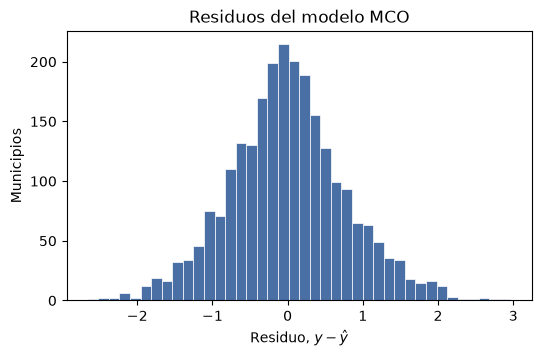

In [10]:
# NORMALIDAD: distribución de los residuos
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(model_data_mun['residual'], bins=40, color='#4a6fa5', edgecolor='white', linewidth=0.5)
ax.set_xlabel(r'Residuo, $y - \hat{y}$')
ax.set_ylabel('Municipios')
ax.set_title('Residuos del modelo MCO');

In [11]:
# Asimetría y curtosis de los residuos (en una normal son 0 y 3); son las mismas que usa la prueba de Jarque-Bera
print(f"Asimetría: {skew(model_data_mun['residual']):.2f}")
print(f"Curtosis:  {kurtosis(model_data_mun['residual'], fisher=False):.2f}")

Asimetría: 0.12
Curtosis:  3.35


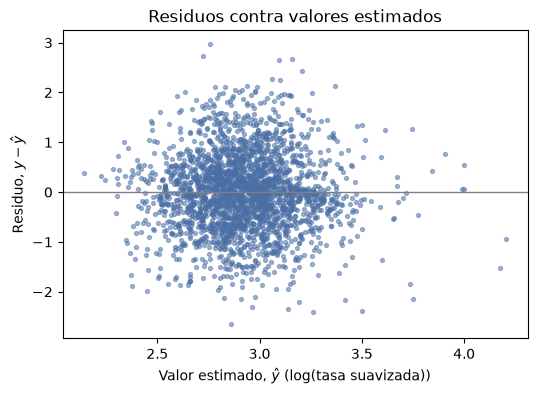

In [12]:
# HETEROCEDASTICIDAD: Residuos contra valores estimados del modelo MCO
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(ols_mun.predy, ols_mun.u, s=8, alpha=0.5, color='#4a6fa5')
ax.axhline(0, color='gray', linewidth=1)
ax.set_xlabel(r'Valor estimado, $\hat{y}$ (log(tasa suavizada))')
ax.set_ylabel(r'Residuo, $y - \hat{y}$')
ax.set_title('Residuos contra valores estimados');

## 3. Análisis espacial de los residuos

**3.1 Construir la matriz de pesos espaciales**

La matriz de pesos espaciales $W$ (2,456 × 2,456) indica qué municipios son vecinos. Se construye con los polígonos municipales del Marco Geoestadístico 2010 (INEGI, 2010b) y, como en Anselin et al. (1996, pp. 81 y 89–90):
* **Contigüidad tipo reina (*queen*):** dos municipios son vecinos si comparten un borde o al menos un vértice.
* **Estandarización por renglón:** cada renglón de $W$ suma 1, así que cada vecino de un municipio pesa $1 / (\text{número de vecinos})$.
* Se usa la misma $W$ para el rezago espacial y para el error ($W_1 = W_2 = W$).

In [13]:
# Polígonos en el mismo orden que model_data_mun (el orden de W debe coincidir con el de y y X)
muns = muns.loc[model_data_mun.index]

# Vecinos por contigüidad tipo reina
w_mun = Queen.from_dataframe(muns, use_index=True)
w_mun.transform = 'r' # estandarizar por renglón

# Revisiones: mismo orden que los datos, ningún municipio sin vecinos y cada renglón de W suma 1
assert list(w_mun.id_order) == list(model_data_mun.index)
assert w_mun.islands == []
assert all(np.isclose(sum(weights), 1) for weights in w_mun.weights.values())

# Vista previa: renglón de Benito Juárez, Ciudad de México (09014), solo con sus vecinos (el resto del renglón es 0)
print("Ejemplo - vecinos (estandarizados) de Benito Juárez, CDMX:")
pd.Series(w_mun.weights['09014'], index=w_mun.neighbors['09014'], name='peso').rename(index=model_data_mun['nom_mun']).round(2)

Ejemplo - vecinos (estandarizados) de Benito Juárez, CDMX:


Álvaro Obregón    0.17
Cuauhtémoc        0.17
Iztapalapa        0.17
Miguel Hidalgo    0.17
Iztacalco         0.17
Coyoacán          0.17
Name: peso, dtype: float64

**3.2 Mapa de los residuos**

Si los residuos no tienen dependencia espacial, los municipios con residuos positivos y negativos deberían repartirse sin un patrón geográfico claro. Sin embargo, observamos en el mapa a continuación que no es así: hay regiones de municipios vecinos donde el modelo predice muy pocos homicidios (ej. en Chihuahua y Sonora) y otras donde el modelo predice demasiados homicidios (ej. Coahuila y la Península de Yucatán).

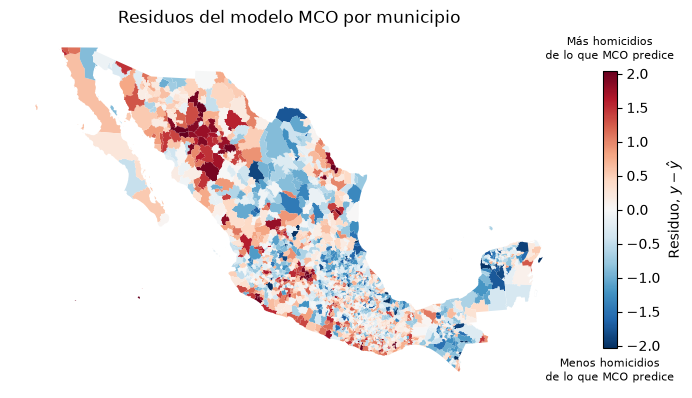

In [14]:
# Mapa de residuos con escala divergente centrada en 0. Un residuo positivo (rojo) indica que el modelo predice menos
# homicidios de los observados; uno negativo (azul), más.
max_abs = model_data_mun['residual'].abs().quantile(0.99)
norm = mcolors.TwoSlopeNorm(vmin=-max_abs, vcenter=0, vmax=max_abs)

fig, ax = plt.subplots(figsize=(9, 6))
muns.assign(residual=model_data_mun['residual']).plot(
    column='residual', cmap='RdBu_r', norm=norm, linewidth=0, ax=ax,
    legend=True, legend_kwds={'label': r'Residuo, $y - \hat{y}$', 'shrink': 0.6},
)
colorbar = fig.axes[-1]
colorbar.text(0.5, 1.03, 'Más homicidios\nde lo que MCO predice', transform=colorbar.transAxes, ha='center', va='bottom', fontsize=8)
colorbar.text(0.5, -0.03, 'Menos homicidios\nde lo que MCO predice', transform=colorbar.transAxes, ha='center', va='top', fontsize=8)
ax.set_axis_off()
ax.set_title('Residuos del modelo MCO por municipio');

**3.3 I de Moran global**

El índice global de Moran $I$ mide la autocorrelación espacial de los residuos en todo el país con un solo valor (Moran, 1950): indica si los municipios vecinos tienen residuos parecidos. Toma valores aproximadamente entre $-1$ y $1$, que se interpretan así:

| $-1$ | $0$ | $1$ |
|:---|:---:|---:|
| ⟵ **Dispersión**: los municipios vecinos tienen residuos opuestos | **Distribución aleatoria** | **Concentración**: los municipios vecinos tienen residuos parecidos ⟶ |

In [15]:
# I de Moran de los residuos de MCO
moran_mun = MoranRes(ols_mun, w_mun, z=True)
print(f'I de Moran: {moran_mun.I:.4f}')
print(f'Valor p: {moran_mun.p_norm:.2g}')

I de Moran: 0.3667
Valor p: 3.4e-201


El índice global de Moran de los residuos es $I = 0.37$, con un valor $p$ mucho menor a $\alpha = 0.05$: rechazamos $H_0$ (que los residuos están distribuidos aleatoriamente en el espacio). Los municipios vecinos tienen residuos parecidos (concentración), lo cual coincide con lo que se ve en el mapa anterior: sí existe un patrón geográfico en la distribución de los residuos.

Las pruebas LM en las siguientes secciones permiten distinguir si esta dependencia espacial está en el error o en el rezago de la variable dependiente.

**3.4 Pruebas LM de rezago, de error y conjunta**

Anselin et al. (1996, p. 80) parten del modelo general (ec. 3), con rezago espacial de la variable dependiente y error espacial autorregresivo:

$$y = \phi W_1 y + X\gamma + u, \qquad u = \psi W_2 u + \varepsilon, \qquad \varepsilon \sim N(0, \sigma^2 I)$$

En otras palabras, la variable dependiente $y$ (en este caso, la tasa de homicidios) depende de tres cosas:
- $X\gamma$: las características (variables independientes) $X$ de ese municipio, multiplicado por sus coeficientes $\gamma$ del modelo MCO.
- $\phi W_1 y$: el rezago espacial. $W_1 y$ representa el promedio de $y$ en los municipios vecinos y $\phi$ indica qué tanto la tasa de un municipio responde a aquella de sus vecinos. Es decir si $\phi  > 0$, existe rezago espacial.
- $u$: el error, lo que $X\gamma$ y $\phi W_1 y$ no explican.

Entonces, $u$ representa el error del modelo y consiste en dos partes:
- $\psi W_2 u$ es el error _espacial_. Si $\psi > 0$, existe error espacial.
- $\varepsilon$ es el error "aleatorio" del modelo: el error que _no_ se explica con patrones geográficos. Tiene una distribución normal con $\mu = 0$.

Las pruebas se calculan con `spreg`, la biblioteca de econometría espacial de PySAL, a partir de los resultados del modelo MCO.

| Prueba | Hipótesis nula | Ecuación | Estadístico |
|---|---|---|---|
| $LM_\phi$ | No hay rezago espacial ($\phi = 0$), suponiendo que no hay error espacial | (13) | $\dfrac{[\tilde u'W_1y/\tilde\sigma^2]^2}{N\tilde J_{\phi\cdot\gamma}}$ |
| $LM_\psi$ | No hay error espacial ($\psi = 0$), suponiendo que no hay rezago espacial | (9) | $\dfrac{[\tilde u'W\tilde u/\tilde\sigma^2]^2}{T}$ |
| $LM_{\phi\psi}$ | No hay ni rezago ni error espacial ($\phi = \psi = 0$) | (15) | $\dfrac{[\tilde u'Wy/\tilde\sigma^2 - \tilde u'W\tilde u/\tilde\sigma^2]^2}{N\tilde J_{\phi\cdot\gamma} - T} + \dfrac{[\tilde u'W\tilde u/\tilde\sigma^2]^2}{T}$ |

En las fórmulas anteriores, $[\tilde u'W_1y/\tilde\sigma^2]^2$ representa qué tan fuerte es la relación, en todos los municipios, entre los residuos y la tasa promedio de los vecinos, sin importar si es positiva o negativa, mientras que $[\tilde u'W\tilde u/\tilde\sigma^2]^2$ representa qué tan fuerte es la relación, en todos los municipios, entre los residuos y el residuo promedio de los vecinos, sin importar si es positiva o negativa. ${N\tilde J_{\phi\cdot\gamma}}$ se puede interpretar como la varianza que tendría $\tilde u'W_1y/\tilde\sigma^2$ si no hubiera rezago espacial, y $T$ como la varianza que tendría $\tilde u'W\tilde u/\tilde\sigma^2$ si no hubiera error espacial.

$LM_\phi$ y $LM_\psi$ son pruebas en una sola dirección: cada una supone que la otra forma de dependencia no existe. $LM_{\phi\psi}$ prueba las dos a la vez, pero si la rechaza no indica cuál de las dos está presente.

In [16]:
# Pruebas LM de spreg: rezago (lml), error (lme), sus versiones robustas (rlml y rlme) y conjunta (sarma)
lm_mun = LMtests(ols_mun, w_mun, tests=['lml', 'lme', 'rlml', 'rlme', 'sarma'])

# Cada prueba es una tupla (estadístico, valor p)
pd.DataFrame({
    'Estadístico': [lm_mun.lml[0], lm_mun.lme[0], lm_mun.sarma[0]],
    'Valor p': [lm_mun.lml[1], lm_mun.lme[1], lm_mun.sarma[1]],
}, index=pd.Index(['LM_φ (rezago)', 'LM_ψ (error)', 'LM_φψ (conjunta)'], name='Prueba')).style.format({'Estadístico': '{:.2f}', 'Valor p': '{:.2g}'})

,Estadístico,Valor p
Prueba,,
LM_φ (rezago),951.21,7.2e-209
LM_ψ (error),902.45,2.9e-198
LM_φψ (conjunta),951.30,2.7e-207


**3.5 Pruebas LM robustas**

$LM_\phi$ y $LM_\psi$ suponen que la otra forma de dependencia no existe. Si sí existe, las dos pruebas pueden rechazar su hipótesis nula aunque solo haya una forma de dependencia: $LM_\psi$ puede detectar un rezago espacial, y $LM_\phi$, un error espacial. La contribución de Anselin et al. (1996) son las versiones **robustas** ($LM^*$), que corrigen cada prueba para que siga siendo válida aunque la otra forma de dependencia también esté presente. Estas pruebas robustas ayudan a distinguir entre cuando realmente existen ambas formas de dependencia (rezago _y_ error espacial) vs. cuando solo existe una. También se calculan con `spreg` a partir de los residuos de MCO:

| Prueba | Hipótesis nula | Ecuación | Estadístico |
|---|---|---|---|
| $LM^*_\phi$ | No hay rezago espacial ($\phi = 0$), aunque haya error espacial | (12) | $\dfrac{[\tilde u'Wy/\tilde\sigma^2 - \tilde u'W\tilde u/\tilde\sigma^2]^2}{N\tilde J_{\phi\cdot\gamma} - T}$ |
| $LM^*_\psi$ | No hay error espacial ($\psi = 0$), aunque haya rezago espacial | (8) | $\dfrac{[\tilde u'W\tilde u/\tilde\sigma^2 - T(N\tilde J_{\phi\cdot\gamma})^{-1}\,\tilde u'Wy/\tilde\sigma^2]^2}{T[1 - T(N\tilde J_{\phi\cdot\gamma})^{-1}]}$ |

Los símbolos son los mismos de la sección 3.4.

La prueba conjunta se descompone en las pruebas robustas y no robustas (ec. 16): $LM_{\phi\psi} = LM_\psi + LM^*_\phi = LM^*_\psi + LM_\phi$.

In [17]:
pd.DataFrame({
    'Estadístico': [lm_mun.rlml[0], lm_mun.rlme[0]],
    'Valor p': [lm_mun.rlml[1], lm_mun.rlme[1]],
}, index=pd.Index(['LM*_φ (rezago robusta)', 'LM*_ψ (error robusta)'], name='Prueba')).style.format({'Estadístico': '{:.2f}', 'Valor p': '{:.2g}'})

,Estadístico,Valor p
Prueba,,
LM*_φ (rezago robusta),48.84,2.8e-12
LM*_ψ (error robusta),0.08,0.77


## 4. Interpretación de resultados

Como en la tabla 2 de Anselin et al. (1996), se reúnen las pruebas LM, comparando $LM_\phi$ y $LM_\psi$ con sus versiones robustas, $LM^*_\phi$ y $LM^*_\psi$, junto con la prueba conjunta $LM_{\phi\psi}$. Los valores con asterisco (\*) son significativos con $\alpha = 0.05$.

In [18]:
# Cada renglón: descripción, valor y valor p
rows = [
    ('Prueba LM conjunta de rezago y error espaciales', f'{lm_mun.sarma[0]:.2f}', lm_mun.sarma[1]),
    ('Prueba LM de error espacial', f'{lm_mun.lme[0]:.2f}', lm_mun.lme[1]),
    ('Prueba LM robusta de error espacial', f'{lm_mun.rlme[0]:.2f}', lm_mun.rlme[1]),
    ('Prueba LM de rezago espacial', f'{lm_mun.lml[0]:.2f}', lm_mun.lml[1]),
    ('Prueba LM robusta de rezago espacial', f'{lm_mun.rlml[0]:.2f}', lm_mun.rlml[1]),
]
# Asterisco en los valores significativos con α = 0.05
pd.DataFrame(
    [(description, value + ('*' if p_value < 0.05 else ''), f'{p_value:.2g}') for description, value, p_value in rows],
    columns=['Descripción', 'Valor', 'Valor p'],
    index=pd.Index(['LM_φψ', 'LM_ψ', 'LM*_ψ', 'LM_φ', 'LM*_φ'], name=''),
)

,Descripción,Valor,Valor p
,,,
LM_φψ,Prueba LM conjunta de rezago y error espaciales,951.30*,2.7e-207
LM_ψ,Prueba LM de error espacial,902.45*,2.9e-198
LM*_ψ,Prueba LM robusta de error espacial,0.08,0.77
LM_φ,Prueba LM de rezago espacial,951.21*,7.2e-209
LM*_φ,Prueba LM robusta de rezago espacial,48.84*,2.8e-12


Sin las pruebas LM robustas, $LM_{\phi\psi}$ identifica que existe _al menos_ una de las dos formas de dependencia espacial en los residuos del modelo, ya sea rezago _y/o_ error espacial. Sin embargo, esta prueba conjunta no puede especificar cuál de las dos está presente, o si lo están ambas.

Las pruebas _no_ robustas ($LM_\phi$ y $LM_\psi$) detectan _ambas_ formas de dependencia espacial de manera estadísticamente significativa. Es decir, según $LM_\phi$ y $LM_\psi$, existe tanto rezago espacial como error espacial en el modelo.

En cambio, con las pruebas robustas ($LM^*_\phi$ y $LM^*_\psi$), solo el rezago espacial sigue siendo estadísticamente significativo ($p < 0.05$). Por lo tanto, _no_ se puede afirmar la presencia de error espacial en este modelo: el resultado de $LM_\psi$ se debe a que esta prueba confunde el rezago con error.

Cabe recordar que las pruebas LM suponen errores homocedásticos y que los residuos de este modelo no lo son (sección 2.4), por lo que estos resultados deben leerse con esa limitación en mente. Teniendo esto en cuenta, los resultados de estas pruebas son más consistentes con un "contagio" de la violencia homicida entre municipios vecinos que con la omisión de una variable importante.

Considerando que el rezago espacial y el error espacial son fenómenos distintos con implicaciones distintas para la validez de un modelo, las pruebas robustas que proponen Anselin et al. son muy valiosas para especificar modelos de regresión con datos espaciales: a partir de los residuos de un solo modelo MCO, indican si conviene estimar un modelo de rezago espacial, uno de error espacial o uno con ambos.

## Referencias

Anselin, L., Bera, A. K., Florax, R. y Yoon, M. J. (1996). Simple diagnostic tests for spatial dependence. *Regional Science and Urban Economics*, *26*(1), 77–104. https://doi.org/10.1016/0166-0462(95)02111-6

Instituto Nacional de Estadística y Geografía. (2010a). *Censo de Población y Vivienda 2010: Principales resultados por localidad (ITER)* [Conjunto de datos]. https://www.inegi.org.mx/programas/ccpv/2010/

Instituto Nacional de Estadística y Geografía. (2010b). *Marco Geoestadístico 2010, versión 5.0.A* [Conjunto de datos]. https://www.inegi.org.mx/temas/mg/

Instituto Nacional de Estadística y Geografía. (2018–2024). *Estadísticas de defunciones registradas: Microdatos, 2018 a 2024* [Conjunto de datos]. https://www.inegi.org.mx/programas/edr/#microdatos

Marshall, R. J. (1991). Mapping disease and mortality rates using empirical Bayes estimators. *Journal of the Royal Statistical Society: Series C (Applied Statistics)*, *40*(2), 283–294. https://doi.org/10.2307/2347593

Moran, P. A. P. (1950). Notes on continuous stochastic phenomena. *Biometrika*, *37*(1/2), 17–23. https://doi.org/10.2307/2332142

Osorio, J. y Beltrán, A. (2020). Enhancing the detection of criminal organizations in Mexico using ML and NLP. En *2020 International Joint Conference on Neural Networks (IJCNN)* (pp. 1–7). IEEE. https://doi.org/10.1109/IJCNN48605.2020.9207039